# Tikhonov-regularised downward continuation (Tikhonov et al., 1968)

Classical baseline, no training. The downward-continuation filter is $e^{kz} / (1 + \alpha k^2 e^{kz})$,
with α chosen in one of two ways:

* **TRDC**: α at the corner (maximum curvature) of the L-curve, using no ground truth.
* **Oracle TRDC**: α minimising the RMS error to the ground truth, i.e. an upper bound for TRDC.

Runs on CPU.

**Evaluation protocol (all notebooks).** The 10 synthetic test grids (32 × 32 nodes, 50 m spacing) are
scaled to [-1, 1] per grid. PSNR, SSIM, relative error (RE) and RMSE are computed on the central 24 × 24
window and reported as mean ± standard deviation (ddof = 0) over the 10 grids. Networks run in full FP32
with deterministic cuDNN (set when `gravdc` is imported, see `gravdc/precision.py`).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # make the gravdc package importable

import numpy as np
import torch

from gravdc import evaluate, format_summary, load_model, load_test_set, save_result, summarize
from gravdc.plotting import show_reconstruction
from gravdc.table2 import compare

DATA_DIR = "../data/test"
RESULTS_DIR = "../results"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.9.0+cu128


## Data
Observation: the multiscale operator (40 steps of 2.5 m = 100 m), as for TTSIDC.

In [2]:
from gravdc import MultiscaleOperator
from gravdc import classical

names, x = load_test_set(DATA_DIR)
A = MultiscaleOperator()  # 40 x 2.5 m = 100 m
y = A(x)
TRDC = dict(perex=(4, 4), z=100, dx=50, dy=50)

## Inference

In [3]:
rec_lcurve, rec_oracle = [], []
for name, f, truth in zip(names, y[:, 0].numpy(), x[:, 0].numpy()):
    alpha_l = classical.lcurve_alpha(f, n=200, alpha_start=1e-5, ratio=1.1, **TRDC)
    alpha_o = classical.oracle_alpha(f, truth, n=2000, alpha_start=0.1, ratio=1.01, **TRDC)
    rec_lcurve.append(classical.tr_down_continue(f, alpha_l, **TRDC))
    rec_oracle.append(classical.tr_down_continue(f, alpha_o, **TRDC))
    print(f"{name:12s} alpha (L-curve) = {alpha_l:9.4f}   alpha (oracle) = {alpha_o:9.4f}")
rec_lcurve = np.stack(rec_lcurve)[:, None]
rec_oracle = np.stack(rec_oracle)[:, None]

data11.mat   alpha (L-curve) =    6.8607   alpha (oracle) =  106.9752
data111.mat  alpha (L-curve) =    7.5468   alpha (oracle) =    5.7959
data211.mat  alpha (L-curve) =    6.8607   alpha (oracle) =  101.7832
data311.mat  alpha (L-curve) =    6.8607   alpha (oracle) =   89.4331
data411.mat  alpha (L-curve) =    6.8607   alpha (oracle) =    5.9124
data511.mat  alpha (L-curve) =    7.5468   alpha (oracle) =   98.7898
data611.mat  alpha (L-curve) =    7.5468   alpha (oracle) =  108.0449
data711.mat  alpha (L-curve) =    7.5468   alpha (oracle) =  106.9752
data811.mat  alpha (L-curve) =    6.8607   alpha (oracle) =  105.9160
data911.mat  alpha (L-curve) =    6.8607   alpha (oracle) =  102.8010


## Metrics

In [4]:
for row, rec in [("Oracle TRDC", rec_oracle), ("TRDC", rec_lcurve)]:
    per_image = evaluate(x, rec)
    compare(row, summarize(per_image))
    save_result(row, per_image, names, RESULTS_DIR)

Oracle TRDC
  metric             this run              Table 2
  PSNR       37.0393 ± 1.9052     37.0393 ± 1.9052  ✓
  SSIM        0.9761 ± 0.0082      0.9761 ± 0.0082  ✓
  RE          0.0424 ± 0.0040      0.0424 ± 0.0040  ✓
  RMSE        0.0282 ± 0.0066      0.0282 ± 0.0066  ✓
TRDC
  metric             this run              Table 2
  PSNR       36.3714 ± 1.7217     36.3714 ± 1.7217  ✓
  SSIM        0.9756 ± 0.0057      0.9756 ± 0.0057  ✓
  RE          0.0457 ± 0.0039      0.0457 ± 0.0039  ✓
  RMSE        0.0303 ± 0.0064      0.0303 ± 0.0064  ✓


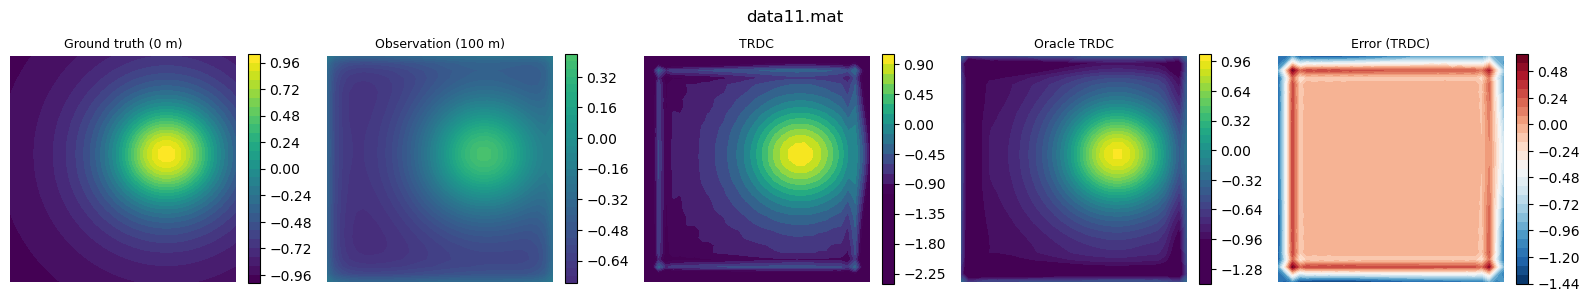

In [5]:
k = 0
show_reconstruction(x[k], y[k], {"TRDC": rec_lcurve[k], "Oracle TRDC": rec_oracle[k]}, title=names[k])